# Edge Realty Investment Strategy — evidence-led analysis
## Executive summary
An independent portfolio case study, not commissioned by Edge Realty. Fixed capital ceiling: **AED 250 million**. Institutional horizon: **2026–2030**. Residential results cover the supplied annual rent only.

This notebook uses only the two supplied workbooks. It introduces no rent growth, occupancy, expense, discount-rate or resale assumptions. Source values are synthetic scenarios, not verified market observations. Correct arithmetic does not validate their commercial realism.

The original mixed-portfolio total-return question cannot be fully answered: residential net expenses and 2030 sale values are absent. Separate, clearly labelled allocation exercises follow instead.

### Executed allocation findings
- Residential finite-candidate allocation: AED 249,867,000 purchase cost; AED 133,000 unspent; AED 17,259,636 supplied annual **gross** rent.
- Institutional income allocation: AED 249,570,961.80 full commitment; AED 429,038.20 unspent; AED 60,651,152.88 recorded **cumulative net** rent for 2026–2030.
- These objectives cover different periods and cost definitions and must not be compared directly. Solver gaps are below 0.1%; these are near-optimal finite-candidate solutions, not guaranteed market investment opportunities.

Execution note: cells were executed sequentially in a fresh Python process with captured tables and figures because this host blocked the standard Jupyter kernel network transport. Standard Jupyter Run All remains to be verified on your computer.

## 1. Questions and answer boundaries
1. Which locations and residential types have the strongest supplied gross yields?
2. Which institutional types and routes have the strongest supplied 2026–2030 net rent and return?
3. Which finite combinations fit AED 250 million, with unspent cash visible?
4. What changes under single-location versus unrestricted allocation?
5. Where are opening delays, outstanding commitments and missing terminal values?
6. What prevents a fair residential/institutional/mixed total-return comparison?

No conservative/optimistic cases are fabricated. Rankings describe supplied scenarios only.

## 2. Setup and reproduction
Place this notebook in `jupyter_notebooks/` and the two original, unchanged Excel files in `data/raw/` in your GitHub project. Alternatively set environment variable `UAE_DATA_DIR` to their folder.

Install in your notebook environment: `%pip install pandas openpyxl numpy scipy matplotlib ipykernel`.
Run all cells in order. Requires SciPy with `scipy.optimize.milp` support. The notebook exports analysis tables to `outputs/analysis/`; it never edits the workbooks.

In [1]:
from pathlib import Path
import os, hashlib, platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import csr_matrix, vstack
from IPython.display import display
pd.options.display.float_format = '{:,.3f}'.format
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.spines.top': False, 'axes.spines.right': False})
BUDGET = 250_000_000
root = Path.cwd().parent if Path.cwd().name == 'jupyter_notebooks' else Path.cwd()
DATA = Path(os.environ.get('UAE_DATA_DIR', root / 'data' / 'raw'))
OUT = root / 'outputs' / 'analysis'
OUT.mkdir(parents=True, exist_ok=True)
print({'Python': platform.python_version(), 'pandas': pd.__version__, 'SciPy': scipy.__version__})

{'Python': '3.15.2', 'pandas': '3.1.1', 'SciPy': '1.18.1'}


## 3. Load exact source sheets and record provenance

In [2]:
import sys
print(sys.executable)

import pandas
import numpy
import matplotlib
import scipy
import openpyxl

print("All required packages are available.")

C:\Users\HP\Documents\edge-realty-investment-strategy\.venv\Scripts\python.exe


All required packages are available.


In [3]:
files = ['A-UAE_Investment_Opportunity_AED.xlsx', 'A-UAE_Institutional_Capital_Forecast_2026_2030.xlsx']
r = pd.read_excel(DATA / files[0], sheet_name='property_purchase_rental')
i = pd.read_excel(DATA / files[1], sheet_name='Institutional_laws')
provenance = pd.DataFrame([{'file': f, 'sha256': hashlib.sha256((DATA/f).read_bytes()).hexdigest()} for f in files])
display(provenance)
display(pd.DataFrame({'dataset':['Residential','Institutional'], 'rows':[len(r),len(i)], 'locations':[r.location.nunique(),i.location.nunique()]}))
# Row identifiers preserve source rows, without pretending that each row is verified stock.
r['row_id'] = ['RES'+str(k+2) for k in range(len(r))]
i['row_id'] = i.candidate_id
assert i.candidate_id.is_unique
assert r.purchase_price_aed.gt(0).all() and i.total_committed_cost_aed.gt(0).all()

,file,sha256
0,A-UAE_Investment_Opportunity_AED.xlsx,f35b39e4f3b1427c430f53659561e900fcf69aecaf6da3...
1,A-UAE_Institutional_Capital_Forecast_2026_2030...,c175bb4f53be0eb5b3b351d6a5e0ced52e84c9dd89e72a...


,dataset,rows,locations
0,Residential,2183,150
1,Institutional,600,25


## 4. Source evidence labels and missingness

In [4]:
display(r.financial_data_basis.value_counts().to_frame('rows'))
display(i.evidence_status.value_counts().to_frame('rows'))
missing = pd.concat([r.isna().sum().rename('residential'), i.isna().sum().rename('institutional')], axis=1)
display(missing.loc[missing.fillna(0).gt(0).any(axis=1)])
print('Exact duplicate rows:', r.drop(columns='row_id').duplicated().sum(), i.drop(columns='row_id').duplicated().sum())
print('Residential repeated project IDs are not necessarily duplicates: bedroom variants share project IDs.')

,rows
financial_data_basis,
Synthetic adjusted price and rent; not market verified,2183


,rows
evidence_status,
"No site, quote, tenant, demand or approval verified",600


,residential,institutional
monthly_rent_aed,16.000,NaN
monthly_rent_usd,16.000,NaN
annual_rent_usd,16.000,NaN
annual_rent_aed,16.000,NaN
gross_rental_yield,16.000,NaN
terminal_net_sale_aed,NaN,33.000
total_profit_aed,NaN,33.000
total_return_pct,NaN,33.000


Exact duplicate rows: 0 0
Residential repeated project IDs are not necessarily duplicates: bedroom variants share project IDs.


## 5. Reconcile arithmetic without replacing source values
Rounding tolerance: AED 1 for monetary comparisons and 0.000001 for ratios. Differences are displayed rather than silently corrected. Missing values are never treated as zero income.

In [5]:
years = list(range(2026,2031))
netcols = [f'net_rent_{y}_aed' for y in years]
checks = {
 'Residential annual vs monthly × 12 (AED)': r.annual_rent_aed-r.monthly_rent_aed*12,
 'Residential stored vs calculated yield': r.gross_rental_yield-r.annual_rent_aed/r.purchase_price_aed,
 'Residential USD purchase conversion (AED)': r.purchase_price_aed-r.purchase_price_usd*r.aed_per_usd,
 'Institutional net-rent sum (AED)': i.cumulative_net_rent_aed-i[netcols].sum(axis=1,min_count=5),
 'Institutional capital reconciliation (AED)': i.total_committed_cost_aed-i.capex_spent_by_2030_aed-i.remaining_capex_aed,
 'Institutional profit reconciliation (AED)': i.total_profit_aed-(i.cumulative_net_rent_aed+i.terminal_net_sale_aed-i.total_committed_cost_aed),
 'Institutional return reconciliation': i.total_return_pct-i.total_profit_aed/i.total_committed_cost_aed
}
audit=pd.DataFrame([{'check':k,'tested_rows':v.notna().sum(),'max_absolute_difference':v.abs().max(), 'outside_tolerance':v.abs().gt(1e-6 if 'yield' in k or 'return reconciliation' in k else 1).sum()} for k,v in checks.items()])
display(audit)
assert audit.outside_tolerance.eq(0).all(), 'Resolve reconciliation failures before using allocations.' 

,check,tested_rows,max_absolute_difference,outside_tolerance
0,Residential annual vs monthly × 12 (AED),2167,0.000,0
1,Residential stored vs calculated yield,2167,0.000,0
2,Residential USD purchase conversion (AED),2183,0.018,0
3,Institutional net-rent sum (AED),600,0.000,0
4,Institutional capital reconciliation (AED),600,0.000,0
5,Institutional profit reconciliation (AED),567,0.000,0
6,Institutional return reconciliation,567,0.000,0


## 6. Residential eligible rows and individual gross yields

In [6]:
re = r.loc[r.annual_rent_aed.notna() & r.annual_rent_aed.ge(0)].copy()
re['calculated_gross_yield'] = re.annual_rent_aed/re.purchase_price_aed
print('Excluded missing-rent rows:',len(r)-len(re))
display(re.nlargest(10,'calculated_gross_yield')[['row_id','project_name','location','bedroom_type','purchase_price_aed','annual_rent_aed','calculated_gross_yield']])

Excluded missing-rent rows: 16


,row_id,project_name,location,bedroom_type,purchase_price_aed,annual_rent_aed,calculated_gross_yield
287,RES289,Al Khawaneej — Fictional Sample 04,Al Khawaneej,Studio,319000,"26,808.000",0.084
379,RES381,Al Rashidiya — Fictional Sample 02,Al Rashidiya,Studio,319000,"26,808.000",0.084
439,RES441,Al Warqa — Fictional Sample 03,Al Warqa,Studio,319000,"26,808.000",0.084
543,RES545,Bukadra — Fictional Sample 02,Bukadra,Studio,319000,"26,808.000",0.084
1451,RES1453,Majan — Fictional Sample 01,Majan,Studio,319000,"26,808.000",0.084
1535,RES1537,Mohammed Bin Rashid City — Fictional Sample 02,Mohammed Bin Rashid City,Studio,319000,"26,808.000",0.084
1695,RES1697,Serena — Fictional Sample 01,Serena,Studio,319000,"26,808.000",0.084
1751,RES1753,The Greens — Fictional Sample 01,The Greens,Studio,319000,"26,808.000",0.084
359,RES361,Al Quoz — Fictional Sample 03,Al Quoz,Studio,324000,"26,808.000",0.083
659,RES661,DAMAC Hills 2 — Fictional Sample 04,DAMAC Hills 2,Studio,324000,"26,808.000",0.083


## 7. Location comparison: cost-weighted gross yields, not average percentages

,rows,cost,annual_gross_rent,gross_yield_pct
location,,,,
Al Habtoor City,8,5848000,"384,984.000",6.583
Majan,8,6047000,"384,984.000",6.367
Bukadra,16,12126000,"769,968.000",6.350
DAMAC Hills 2,24,18835000,"1,154,952.000",6.132
Uptown Dubai,12,9682000,"577,476.000",5.964
Al Wasl,12,9814000,"577,476.000",5.884
Dubai Production City,20,16423000,"963,576.000",5.867
Mudon,12,9980000,"577,476.000",5.786
Dubai World Central,8,6774000,"384,984.000",5.683


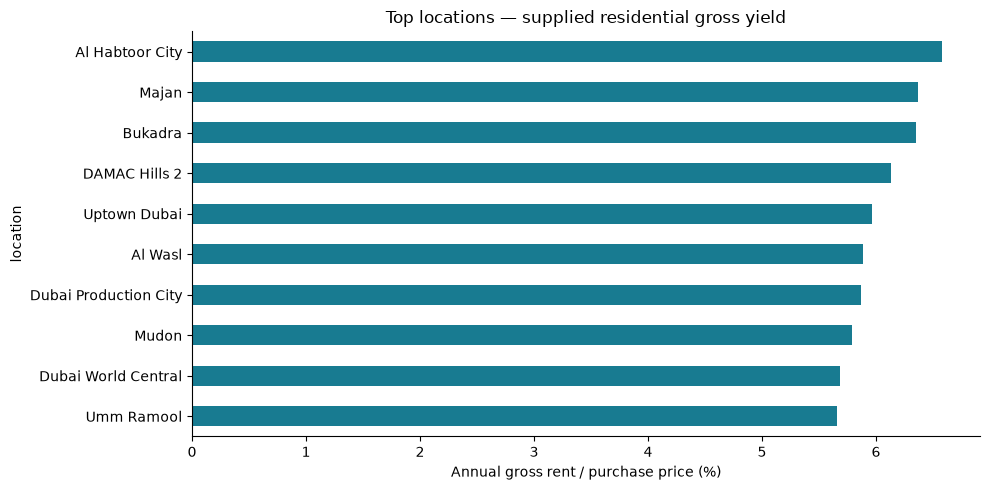

In [7]:
loc = re.groupby('location').agg(rows=('row_id','size'),cost=('purchase_price_aed','sum'),annual_gross_rent=('annual_rent_aed','sum'))
loc['gross_yield_pct']=100*loc.annual_gross_rent/loc.cost
loc=loc.sort_values('gross_yield_pct',ascending=False)
display(loc.head(10))
loc.head(10).gross_yield_pct.sort_values().plot.barh(color='#187b91',title='Top locations — supplied residential gross yield')
plt.xlabel('Annual gross rent / purchase price (%)'); plt.tight_layout(); plt.show()

## 8. Bedroom mix

In [8]:
bed = re.groupby('bedroom_type').agg(rows=('row_id','size'),cost=('purchase_price_aed','sum'),rent=('annual_rent_aed','sum'))
bed['gross_yield_pct']=100*bed.rent/bed.cost
display(bed.sort_values('gross_yield_pct',ascending=False))

,rows,cost,rent,gross_yield_pct
bedroom_type,,,,
Studio,528,375921000,"15,982,980.000",4.252
2-bedroom,542,856887000,"34,375,236.000",4.012
3-bedroom,538,1089037000,"43,461,960.000",3.991
1-bedroom,539,640256000,"25,272,072.000",3.947
7-bedroom,1,18567000,"501,816.000",2.703
6-bedroom,2,54228000,"1,012,884.000",1.868
4-bedroom,12,131732000,"2,393,808.000",1.817
5-bedroom,5,111347000,"1,879,812.000",1.688


## 9. Institutional time horizon and incomplete exits

In [9]:
display(i.groupby(['opening_year','delivery_route']).agg(candidates=('candidate_id','size'),commitment=('total_committed_cost_aed','sum'),remaining=('remaining_capex_aed','sum')))
print('Missing terminal values:', i.terminal_net_sale_aed.isna().sum())
print('Candidates individually exceeding the budget:', i.total_committed_cost_aed.gt(BUDGET).sum())
print('Pre-opening rent violations:', sum(((i.opening_year>y)&i[f'net_rent_{y}_aed'].ne(0)).sum() for y in years))

candidates         commitment  remaining
opening_year delivery_route                                                  
2027         Buy completed facility         100  9,227,582,560.550          0
             Develop facility                 9     36,466,723.800          0
2028         Buy completed facility         100 11,072,072,856.000          0
             Develop facility                66  3,200,036,145.000          0
2029         Buy completed facility         100 12,618,963,323.900          0
             Develop facility                99  9,404,602,526.400          0
2030         Develop facility                93 11,332,799,778.000          0
2031         Develop facility                33  7,982,770,080.000          0

Missing terminal values: 33
Candidates individually exceeding the budget: 58
Pre-opening rent violations: 0


## 10. Institutional type and route performance

In [10]:
inst = i.groupby(['institution_type','delivery_route']).agg(rows=('candidate_id','size'),cost=('total_committed_cost_aed','sum'),net_rent=('cumulative_net_rent_aed','sum'))
inst['five_year_net_income_on_cost_pct']=100*inst.net_rent/inst.cost
display(inst.sort_values('five_year_net_income_on_cost_pct',ascending=False).head(12))
# Total return ranks exclude missing exit valuations.
display(i.dropna(subset=['total_return_pct']).nlargest(10,'total_return_pct')[['candidate_id','location','institution_type','delivery_route','total_committed_cost_aed','cumulative_net_rent_aed','total_return_pct']])

rows              cost  \
institution_type              delivery_route                                   
Nursery / creche              Develop facility          25   118,457,266.200   
                              Buy completed facility    25   123,225,484.200   
Music / performing arts       Buy completed facility    25   633,622,500.000   
Fashion / design institute    Buy completed facility    25   851,182,384.500   
Vocational academy            Buy completed facility    25   916,847,274.000   
Scientific research institute Buy completed facility    25 5,970,525,000.000   
Clinical training institute   Buy completed facility    25 2,770,122,936.000   
Secondary school              Buy completed facility    25 3,062,323,152.000   
Primary school                Buy completed facility    25 1,549,112,500.000   
University / college          Buy completed facility    25 7,174,317,168.000   
Middle school                 Buy completed facility    25 2,241,132,093.000   
K–12 school                   Buy completed facility    25 5,440,050,000.000   

                                                              net_rent  \
institution_type              delivery_route                             
Nursery / creche              Develop facility          22,968,604.740   
                              Buy completed facility    22,968,604.740   
Music / performing arts       Buy completed facility   109,783,189.245   
Fashion / design institute    Buy completed facility   141,939,933.871   
Vocational academy            Buy completed facility   150,630,133.904   
Scientific research institute Buy completed facility   966,092,065.360   
Clinical training institute   Buy completed facility   447,593,323.146   
Secondary school              Buy completed facility   459,372,094.808   
Primary school                Buy completed facility   228,349,033.631   
University / college          Buy completed facility 1,042,824,003.952   
Middle school                 Buy completed facility   323,275,441.225   
K–12 school                   Buy completed facility   761,163,445.435   

                                                      five_year_net_income_on_cost_pct  
institution_type              delivery_route                                            
Nursery / creche              Develop facility                                  19.390  
                              Buy completed facility                            18.639  
Music / performing arts       Buy completed facility                            17.326  
Fashion / design institute    Buy completed facility                            16.676  
Vocational academy            Buy completed facility                            16.429  
Scientific research institute Buy completed facility                            16.181  
Clinical training institute   Buy completed facility                            16.158  
Secondary school              Buy completed facility                            15.001  
Primary school                Buy completed facility                            14.741  
University / college          Buy completed facility                            14.536  
Middle school                 Buy completed facility                            14.425  
K–12 school                   Buy completed facility                            13.992

,candidate_id,location,institution_type,delivery_route,total_committed_cost_aed,cumulative_net_rent_aed,total_return_pct
0,INST0001,Academic City,Nursery / creche,Develop facility,"4,051,858.200","1,081,235.720",0.160
72,INST0073,Al Garhoud,Nursery / creche,Develop facility,"4,051,858.200","1,081,235.720",0.160
144,INST0145,Al Quoz,Nursery / creche,Develop facility,"4,051,858.200","1,081,235.720",0.160
216,INST0217,Business Bay,Nursery / creche,Develop facility,"4,051,858.200","1,081,235.720",0.160
288,INST0289,Dubai Investment Park,Nursery / creche,Develop facility,"4,051,858.200","1,081,235.720",0.160
360,INST0361,Dubai South,Nursery / creche,Develop facility,"4,051,858.200","1,081,235.720",0.160
432,INST0433,Jumeirah Village Circle,Nursery / creche,Develop facility,"4,051,858.200","1,081,235.720",0.160
504,INST0505,Town Square,Nursery / creche,Develop facility,"4,051,858.200","1,081,235.720",0.160
576,INST0577,Jumeirah Lake Towers,Nursery / creche,Develop facility,"4,051,858.200","1,081,235.720",0.160
1,INST0002,Academic City,Nursery / creche,Buy completed facility,"4,214,956.200","1,081,235.720",0.115


## 11. Paired purchase-versus-development comparison
Compare routes only within a concept; these are alternatives, not two separate investments. A cost or income difference reflects workbook design, not proven market superiority.

In [11]:
assert not i.duplicated(['concept_id','delivery_route']).any()
pairs=i.pivot(index='concept_id',columns='delivery_route',values=['total_committed_cost_aed','cumulative_net_rent_aed'])
delta=pd.DataFrame({'buy_minus_develop_cost':pairs['total_committed_cost_aed']['Buy completed facility']-pairs['total_committed_cost_aed']['Develop facility'], 'buy_minus_develop_net_rent':pairs['cumulative_net_rent_aed']['Buy completed facility']-pairs['cumulative_net_rent_aed']['Develop facility']})
display(delta.describe())

,buy_minus_develop_cost,buy_minus_develop_net_rent
count,300.000,300.000
mean,"3,206,478.291","9,572,255.893"
std,"2,963,517.259","10,224,245.066"
min,"163,098.000",0.000
25%,"887,818.125","2,217,469.153"
50%,"2,090,283.500","4,394,566.141"
75%,"4,413,675.000","14,989,941.845"
max,"10,605,300.000","32,637,741.467"


## 12. Allocation rules — decision constraints, not financial assumptions
Binary selection: at most one occurrence of each supplied residential row; at most one delivery route per institutional concept. This is a **finite-candidate exercise**, not a claim of available inventory. Unit quantities are unknown, so unlimited replication is prohibited.

Residential ceiling covers **purchase prices only**; acquisition fees are missing. Institutional ceiling reserves **full committed cost**, including capital due after 2030. The two models therefore cannot be ranked as equivalent net-return portfolios.

Single-location portfolios may choose any rows in one location. Unrestricted portfolios may span locations but are **not forced to diversify**. Mixed net-return optimization is withheld.

In [12]:
def allocate(df, cost, objective, concept=None):
    d=df.dropna(subset=[cost,objective]).reset_index(drop=True).copy()
    if d.empty: return d, {'status':'no eligible rows'}
    rows=[csr_matrix((d[cost].to_numpy()/BUDGET).reshape(1,-1))]
    upper=[1.0]
    if concept:
        groups=pd.Categorical(d[concept])
        rows.append(csr_matrix((np.ones(len(d)),(groups.codes,np.arange(len(d)))),shape=(len(groups.categories),len(d))))
        upper.extend([1.0]*len(groups.categories))
    res=milp(c=-d[objective].to_numpy()/1e6, integrality=np.ones(len(d)),bounds=Bounds(0,1),
        constraints=LinearConstraint(vstack(rows),-np.inf,np.array(upper)), options={'time_limit':30,'mip_rel_gap':0.001})
    if res.x is None: raise RuntimeError(res.message)
    chosen=d.loc[res.x>0.5].copy()
    spent=chosen[cost].sum()
    assert spent<=BUDGET+0.01
    if concept: assert chosen[concept].is_unique
    return chosen, {'status':res.message,'gap':getattr(res,'mip_gap',None),'selected_rows':len(chosen),
        'locations':chosen.location.nunique(),'committed_aed':spent,'unspent_aed':BUDGET-spent,
        'objective_aed':chosen[objective].sum()}
# A solver gap <=0.1% is permitted; inspect status/gap before claiming optimality.
res_port,res_stats=allocate(re,'purchase_price_aed','annual_rent_aed')
inst_port,inst_stats=allocate(i,'total_committed_cost_aed','cumulative_net_rent_aed','concept_id')
profit_port,profit_stats=allocate(i,'total_committed_cost_aed','total_profit_aed','concept_id')
display(pd.DataFrame([res_stats,inst_stats,profit_stats],index=['Residential annual GROSS rent','Institutional 2026–2030 NET rent','Institutional supplied total profit']))

,status,gap,selected_rows,locations,committed_aed,unspent_aed,objective_aed
Residential annual GROSS rent,Optimization terminated successfully. (HiGHS S...,0.000,358,67,"249,867,000.000","133,000.000","17,259,636.000"
Institutional 2026–2030 NET rent,Optimization terminated successfully. (HiGHS S...,0.001,19,18,"249,570,961.800","429,038.200","60,651,152.876"
Institutional supplied total profit,Optimization terminated successfully. (HiGHS S...,0.000,25,25,"246,947,179.800","3,052,820.200","17,807,408.114"


## 13. Single-location versus unrestricted allocations

In [13]:
records=[]
for sector,frame,cost,obj,group in [('Residential',re,'purchase_price_aed','annual_rent_aed',None),('Institutional',i,'total_committed_cost_aed','cumulative_net_rent_aed','concept_id')]:
    for location,part in frame.groupby('location'):
        _,stats=allocate(part,cost,obj,group)
        records.append({'sector':sector,'location':location,**stats})
concentrated=pd.DataFrame(records)
display(concentrated.sort_values(['sector','objective_aed'],ascending=[True,False]).groupby('sector').head(5))
for sector,stats in [('Residential',res_stats),('Institutional',inst_stats)]:
    best=concentrated.loc[concentrated.sector.eq(sector)].sort_values('objective_aed',ascending=False).iloc[0]
    print(sector, 'best single location:',best.location,'; unrestricted objective gain AED:',round(stats['objective_aed']-best.objective_aed,2))
print('Unrestricted sets include every concentrated option; this comparison alone does not establish lower risk.')

,sector,location,status,gap,selected_rows,locations,committed_aed,unspent_aed,objective_aed
152,Institutional,Al Furjan,Optimization terminated successfully. (HiGHS S...,0.000,3,1,"244,934,935.800","5,065,064.200","52,768,634.832"
155,Institutional,Al Khawaneej,Optimization terminated successfully. (HiGHS S...,0.000,3,1,"244,934,935.800","5,065,064.200","52,768,634.832"
158,Institutional,Arjan,Optimization terminated successfully. (HiGHS S...,0.000,3,1,"244,934,935.800","5,065,064.200","52,768,634.832"
162,Institutional,Dubai Hills Estate,Optimization terminated successfully. (HiGHS S...,0.000,3,1,"244,934,935.800","5,065,064.200","52,768,634.832"
165,Institutional,Dubai Silicon Oasis,Optimization terminated successfully. (HiGHS S...,0.000,3,1,"244,934,935.800","5,065,064.200","52,768,634.832"
37,Residential,Business Bay,Optimization terminated successfully. (HiGHS S...,0.000,71,1,"249,878,000.000","122,000.000","7,557,852.000"
76,Residential,Emaar Beachfront,Optimization terminated successfully. (HiGHS S...,0.000,28,1,"73,421,000.000","176,579,000.000","2,526,504.000"
49,Residential,Downtown Dubai,Optimization terminated successfully. (HiGHS S...,0.000,28,1,"71,417,000.000","178,583,000.000","2,503,500.000"
116,Residential,Palm Jumeirah,Optimization terminated successfully. (HiGHS S...,0.000,24,1,"66,721,000.000","183,279,000.000","2,181,792.000"
117,Residential,Port De La Mer,Optimization terminated successfully. (HiGHS S...,0.000,24,1,"59,542,000.000","190,458,000.000","2,138,904.000"


Residential best single location: Business Bay ; unrestricted objective gain AED: 9701784.0
Institutional best single location: Al Furjan ; unrestricted objective gain AED: 7882518.04
Unrestricted sets include every concentrated option; this comparison alone does not establish lower risk.


## 14. Selected institutional cash flows, commitments and concentration

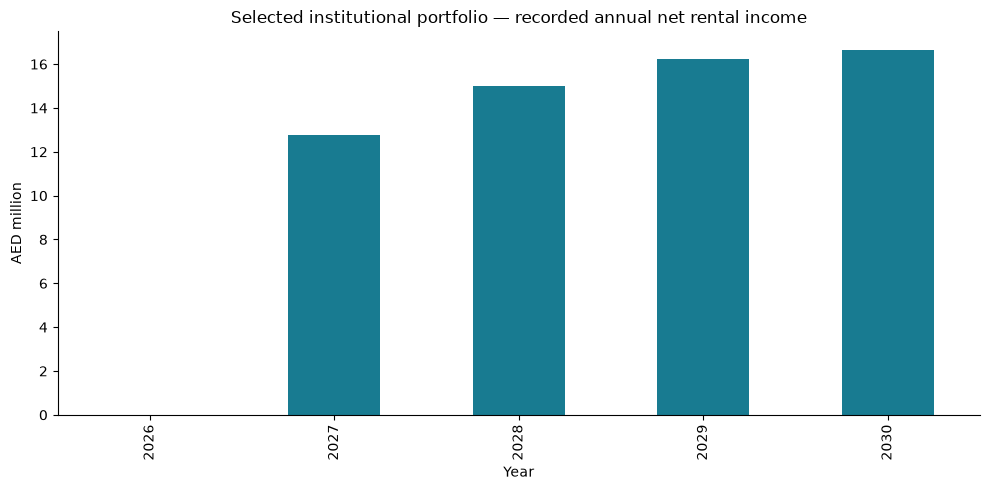

,cost,net_rent
location,,
Dubai Design District,"33,534,487.500","7,739,912.583"
Dubai Healthcare City,"28,767,595.500","6,792,378.240"
Nad Al Sheba,"21,543,165.000","5,198,248.653"
Al Furjan,"21,543,165.000","5,198,248.653"
Arjan,"21,543,165.000","5,198,248.653"
Dubai Hills Estate,"21,543,165.000","5,198,248.653"
Dubai Studio City,"21,543,165.000","5,198,248.653"
Dubailand,"21,543,165.000","5,198,248.653"
Dubai Silicon Oasis,"21,543,165.000","5,198,248.653"


Selected outstanding capex AED: 0
Selected rows with missing terminal values: 0
Supplied portfolio total profit AED: 15204037.355699461


In [14]:
annual=inst_port[netcols].sum()
annual.index=years
annual.div(1e6).plot.bar(color='#187b91',title='Selected institutional portfolio — recorded annual net rental income')
plt.ylabel('AED million');plt.xlabel('Year');plt.tight_layout();plt.show()
display(inst_port.groupby('location').agg(cost=('total_committed_cost_aed','sum'),net_rent=('cumulative_net_rent_aed','sum')).sort_values('cost',ascending=False))
print('Selected outstanding capex AED:',inst_port.remaining_capex_aed.sum())
print('Selected rows with missing terminal values:',inst_port.terminal_net_sale_aed.isna().sum())
# Do not silently sum partial exit valuations.
if inst_port.total_profit_aed.notna().all():
    print('Supplied portfolio total profit AED:',inst_port.total_profit_aed.sum())
else:
    print('Full portfolio total profit unavailable: at least one exit value is missing.')

## 15. Export reproducible analysis tables

In [15]:
for name,table in {'source_provenance':provenance,'arithmetic_audit':audit,'residential_location_summary':loc.reset_index(),'residential_selected':res_port,'institutional_income_selected':inst_port,'institutional_profit_selected':profit_port,'single_location_allocations':concentrated}.items():
    table.to_csv(OUT/f'{name}.csv',index=False)
print('Exports:',OUT)

Exports: C:\Users\HP\Documents\edge-realty-investment-strategy\outputs\analysis


## 16. Findings and limits
The executed tables above answer gross-yield rankings, institutional income/return rankings, constrained candidate allocation, and concentration comparisons. Selection is calculated afresh; original `selected` flags are not presented as recommendations.

**Not established:** which mixed portfolio has the highest 2030 net total return; true market demand; verified asset availability; lower risk from diversification; conservative/base/optimistic outcomes; institutional operator profitability.

To complete the original comparison, obtain residential acquisition expenses, rental availability dates, vacancy, landlord operating costs, annual cash flows and sale proceeds on a consistent basis. Obtain verified institutional land/site approvals, tenant leases and cost quotes. Do not use residential `building_cost_scenario_aed` as unit acquisition cost: its documented basis is a reverse calculation, not a building valuation.

Institutional source forecasts already embed assumptions. This notebook audits and uses their stored values, without claiming to independently verify them. No new financial forecasts have been introduced.